<a href="https://colab.research.google.com/github/mchua03/machinelearning/blob/main/carValueEstimator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
def estimate_home_value(size_in_sqft, number_of_bedrooms):
    # Assume all homes are worth at least $50,000
    value = 50000
    # Adjust value estimate based on size of house
    value = value + (size_in_sqft * 92)
    # Adjust value estimate based on number of bedrooms
    value = value + (number_of_bedrooms * 10000)

    return value

# Estimate value of our house:
# - 5 bedrooms
# - 3800 sq ft
# Actual value: $450,000

value = estimate_home_value(3800, 5)

print("Estimated valued:")

print(value)

Estimated valued:
449600


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [ ]:
df_raw = pd.read_csv("carprice.csv")
df = df_raw.drop(columns=["car_ID"])
df

,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,111,5000,21,27,13495.0
1,88.6,168.8,64.1,48.8,2548,130,3.47,2.68,9.0,111,5000,21,27,16500.0
2,94.5,171.2,65.5,52.4,2823,152,2.68,3.47,9.0,154,5000,19,26,16500.0
3,99.8,176.6,66.2,54.3,2337,109,3.19,3.40,10.0,102,5500,24,30,13950.0
4,99.4,176.6,66.4,54.3,2824,136,3.19,3.40,8.0,115,5500,18,22,17450.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
200,109.1,188.8,68.9,55.5,2952,141,3.78,3.15,9.5,114,5400,23,28,16845.0
201,109.1,188.8,68.8,55.5,3049,141,3.78,3.15,8.7,160,5300,19,25,19045.0
202,109.1,188.8,68.9,55.5,3012,173,3.58,2.87,8.8,134,5500,18,23,21485.0
203,109.1,188.8,68.9,55.5,3217,145,3.01,3.40,23.0,106,4800,26,27,22470.0


In [ ]:
y = df['price']
X = df.drop(columns=['price'])

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y,
train_size=0.7, random_state=2026)

In [ ]:
linR = LinearRegression()
linR.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred = linR.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
print(mse)

15555418.768229477


In [ ]:
import pandas as pd

car_values = [100, 200, 70, 55, 3000, 200, 3.5, 3.4, 9, 200, 5500, 25, 30]

car_df = pd.DataFrame(
    [car_values],
    columns=linR.feature_names_in_
)

price_pred = linR.predict(car_df)

print("Predicted car price:", price_pred[0])

Predicted car price: 24424.65489594599


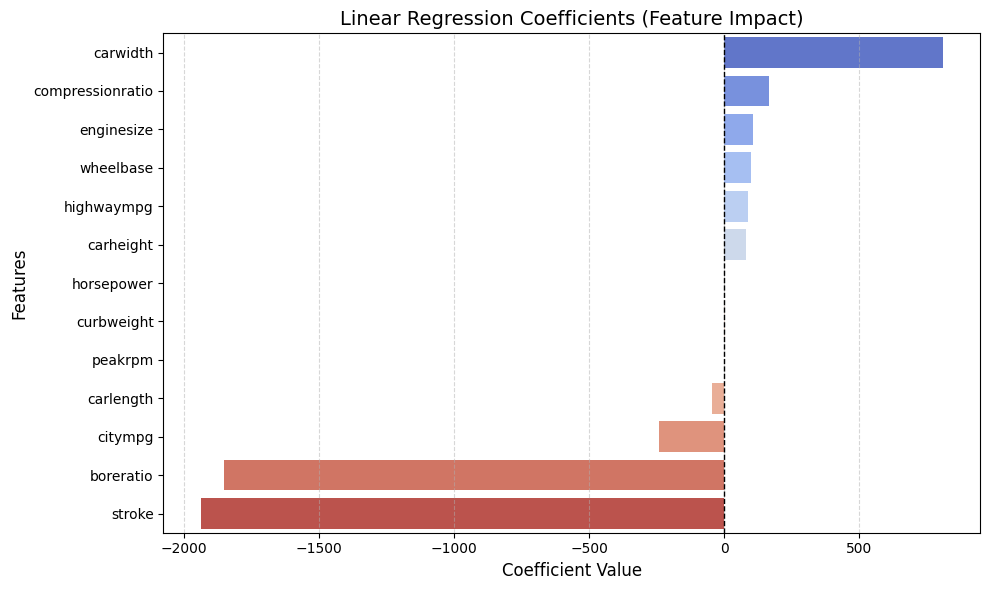

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Prepare data for plotting
coef_df = pd.DataFrame({
    'Feature': linR.feature_names_in_,
    'Coefficient': linR.coef_
})

# Sort by coefficient value for better readability
coef_df = coef_df.sort_values(by='Coefficient', ascending=False)

# Plot the coefficients
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Coefficient',
    y='Feature',
    data=coef_df,
    palette='coolwarm',
    hue='Feature',
    legend=False
)
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.title('Linear Regression Coefficients (Feature Impact)', fontsize=14)
plt.xlabel('Coefficient Value', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import r2_score

# Calculate R-squared score using the test set
r2 = r2_score(y_test, y_pred)
print(f"R-squared (R2) Score on Test Set: {r2:.4f}")

R-squared (R2) Score on Test Set: 0.7304


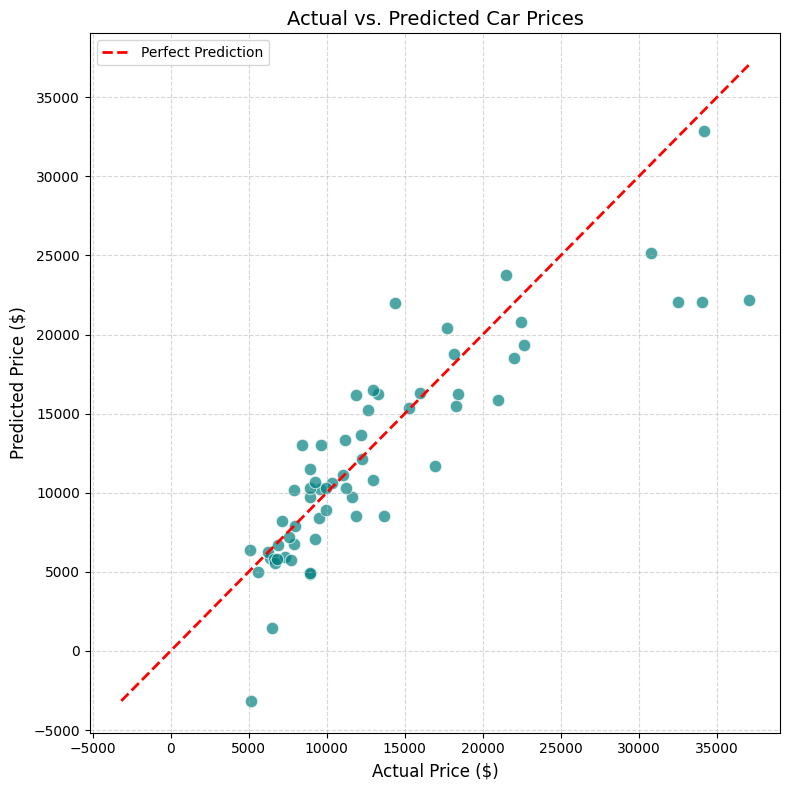

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set the plot size
plt.figure(figsize=(8, 8))

# Create a scatter plot
sns.scatterplot(x=y_test, y=y_pred, alpha=0.7, color='teal', edgecolor='w', s=80)

# Plot a diagonal line representing perfect prediction (y = x)
min_val = min(min(y_test), min(y_pred))
max_val = max(max(y_test), max(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Prediction')

# Customize chart labels and title
plt.title('Actual vs. Predicted Car Prices', fontsize=14)
plt.xlabel('Actual Price ($)', fontsize=12)
plt.ylabel('Predicted Price ($)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

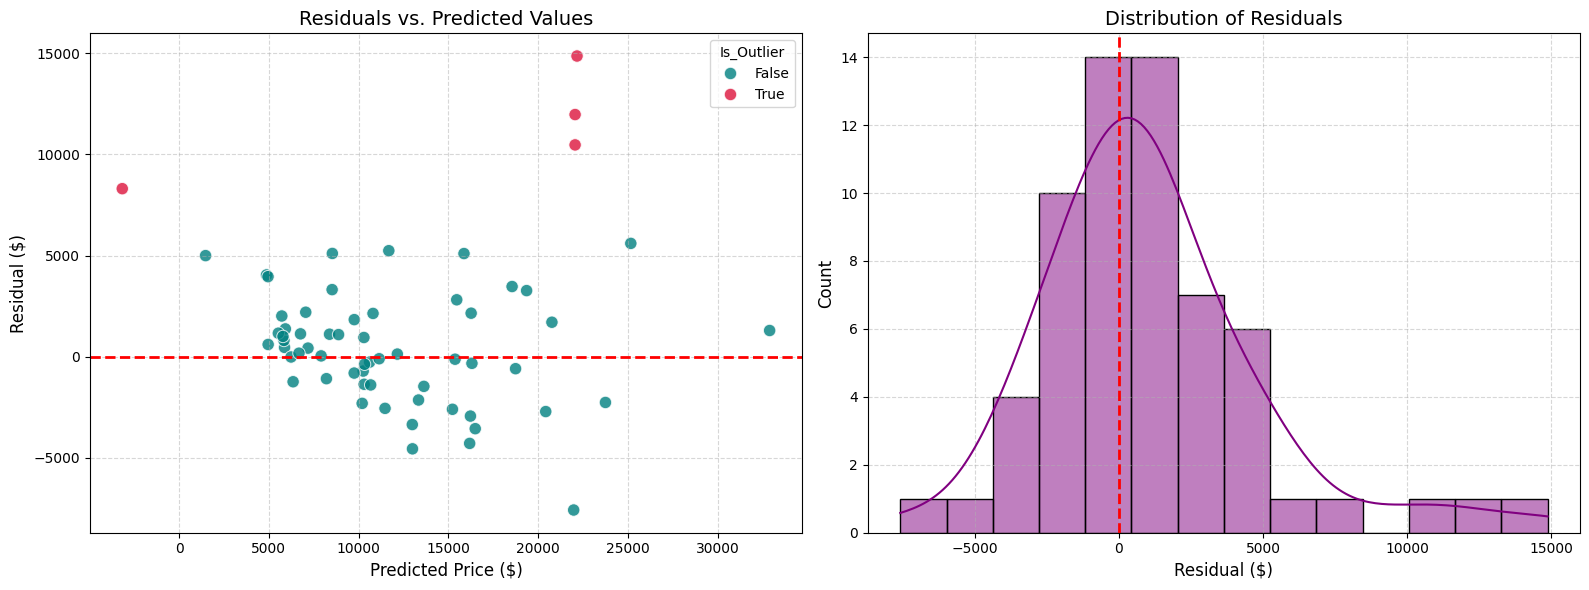

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. Calculate the residuals
residuals = y_test - y_pred

# Create a DataFrame for analysis
analysis_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred,
    'Residual': residuals
})

# Define threshold for extreme residuals (e.g., standard deviations away)
std_residual = residuals.std()
mean_residual = residuals.mean()
analysis_df['Is_Outlier'] = (analysis_df['Residual'].abs() > 2 * std_residual)

# 2. Setup subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left Plot: Residuals vs. Predicted (Homoscedasticity Check)
sns.scatterplot(data=analysis_df, x='Predicted', y='Residual', hue='Is_Outlier', palette={False: 'teal', True: 'crimson'}, ax=axes[0], s=80, alpha=0.8)
axes[0].axhline(0, color='red', linestyle='--', linewidth=2)
axes[0].set_title('Residuals vs. Predicted Values', fontsize=14)
axes[0].set_xlabel('Predicted Price ($)', fontsize=12)
axes[0].set_ylabel('Residual ($)', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Right Plot: Distribution of Residuals
sns.histplot(residuals, kde=True, color='purple', ax=axes[1])
axes[1].axvline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_title('Distribution of Residuals', fontsize=14)
axes[1].set_xlabel('Residual ($)', fontsize=12)
axes[1].set_ylabel('Count', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
# Display the most extreme residuals (outliers)
outliers = analysis_df[analysis_df['Is_Outlier']].copy()
outliers['Absolute_Error'] = outliers['Residual'].abs()
display(outliers.sort_values(by='Absolute_Error', ascending=False))

,Actual,Predicted,Residual,Is_Outlier,Absolute_Error
128,37028.0,22160.601382,14867.398618,True,14867.398618
127,34028.0,22053.821413,11974.178587,True,11974.178587
126,32528.0,22053.821413,10474.178587,True,10474.178587
18,5151.0,-3159.649556,8310.649556,True,8310.649556
